# 07 — Retrieval evaluation mechanics

## Objective

Compute page Hit@k from ranked pages and known evidence pages, while keeping mechanics-only examples separate from the empty verified project evaluation set.

## Concept

For question $i$ with evidence pages $E_i$ and retrieved top-$k$ pages $R_i^{(k)}$,

$$
\operatorname{Hit@k}_i = \mathbf{1}[E_i \cap R_i^{(k)} \neq \varnothing].
$$

Mean Hit@k is the fraction of questions for which at least one evidence page was retrieved. It does not measure whether all required evidence was found.

In [1]:
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
SLIDES_PDF = PROJECT_ROOT / "data" / "documents" / "ch2.pdf"
QUESTIONS_CSV = PROJECT_ROOT / "data" / "annotations" / "questions.csv"

## Setup — rebuild the transparent lexical retriever

Each notebook remains independently executable; no state is imported from notebook 06.

In [2]:
page_numbers = [9, 17, 49, 65]
with pymupdf.open(SLIDES_PDF) as document:
    page_texts = {page: document[page - 1].get_text("text", sort=True) for page in page_numbers}


def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())


vocabulary = sorted({token for text in page_texts.values() for token in tokenize(text)})
index = {token: position for position, token in enumerate(vocabulary)}


def vectorize(text):
    vector = np.zeros(len(vocabulary), dtype=float)
    for token, count in Counter(tokenize(text)).items():
        if token in index:
            vector[index[token]] = count
    return vector


def cosine_similarity(left, right):
    denominator = np.linalg.norm(left) * np.linalg.norm(right)
    return 0.0 if denominator == 0 else float(np.dot(left, right) / denominator)


document_vectors = {page: vectorize(text) for page, text in page_texts.items()}

def rank_pages(query):
    query_vector = vectorize(query)
    return sorted(
        document_vectors,
        key=lambda page: cosine_similarity(query_vector, document_vectors[page]),
        reverse=True,
    )

## Execution — mechanics-only cases

These two cases are hand-selected to verify the metric calculation. They are not added to `questions.csv`, are not claimed as a benchmark, and must not be reported as project performance.

In [3]:
mechanics_cases = pd.DataFrame(
    [
        {"case_id": "M001", "query": "usual conjugate pairs table", "evidence_pages": {49}},
        {"case_id": "M002", "query": "Cromwell rule", "evidence_pages": {9}},
    ]
)
mechanics_cases["ranking"] = mechanics_cases["query"].map(rank_pages)
mechanics_cases[["case_id", "query", "evidence_pages", "ranking"]]

,case_id,query,evidence_pages,ranking
0,M001,usual conjugate pairs table,{49},"[49, 9, 17, 65]"
1,M002,Cromwell rule,{9},"[9, 17, 49, 65]"


## Implementation — calculate Hit@k

In [4]:
def hit_at_k(evidence_pages, ranking, k):
    return int(bool(set(evidence_pages) & set(ranking[:k])))


metric_rows = []
for k in range(1, len(page_numbers) + 1):
    hits = [
        hit_at_k(row.evidence_pages, row.ranking, k)
        for row in mechanics_cases.itertuples(index=False)
    ]
    metric_rows.append({"k": k, "hit_rate": sum(hits) / len(hits), "hits": sum(hits)})

mechanics_metrics = pd.DataFrame(metric_rows)
mechanics_metrics

,k,hit_rate,hits
0,1,1.0,2
1,2,1.0,2
2,3,1.0,2
3,4,1.0,2


## Inspection — metric behavior

Hit@k cannot decrease as k increases because the retrieved set only grows. The chart is explicitly a metric wiring check, not a project result.

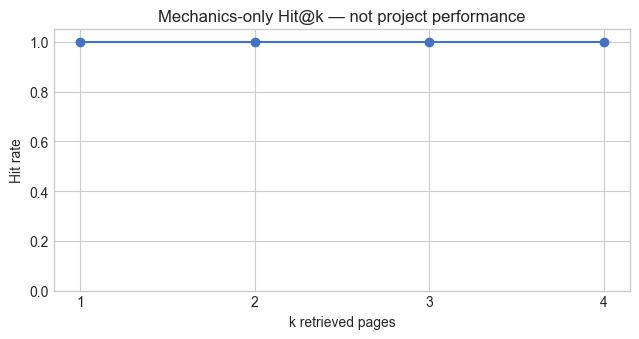

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(mechanics_metrics["k"], mechanics_metrics["hit_rate"], marker="o", color="#4472C4")
ax.set_title("Mechanics-only Hit@k — not project performance")
ax.set_xlabel("k retrieved pages")
ax.set_ylabel("Hit rate")
ax.set_xticks(mechanics_metrics["k"])
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Validation and project readiness gate

In [6]:
assert mechanics_metrics["hit_rate"].between(0, 1).all()
assert mechanics_metrics["hit_rate"].is_monotonic_increasing
assert hit_at_k({49}, [9, 49], 1) == 0
assert hit_at_k({49}, [9, 49], 2) == 1

project_questions = pd.read_csv(QUESTIONS_CSV)
verified_project_questions = project_questions.loc[project_questions["status"] == "verified"]
ready_for_real_retrieval_evaluation = not verified_project_questions.empty

print("Verified project questions:", len(verified_project_questions))
print("Ready for real retrieval evaluation:", ready_for_real_retrieval_evaluation)

Verified project questions: 0
Ready for real retrieval evaluation: False


## Next step

`08_text_qa_with_citations.ipynb` constructs an auditable text-only context, defines a citation contract, and validates response parsing without making an unconfigured model call.